# CS 4372 Homework 2 - Vinay A. Nair

Chosen UCI Dataset: Heart Disease

This project aims to predict whether an individual has heart disease using the Cleveland subset of the UCI Heart Disease dataset. The dataset contains 303 records and 13 predictor variables, including age, chest pain type, resting blood pressure, and cholesterol. The target variable is converted into two classes: absence of heart disease (0) and presence of heart disease (1) The analysis includes data preprocessing, exploratory analysis, hyperparameter tuning, and the construction and comparison of Decision Tree, Random Forest, AdaBoost, and XGBoost classifiers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [4]:
print("Predictor variables:")
print(X.head())

print("\nOriginal target variable:")
print(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Predictor variables:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  

Original target variable:
   num
0    0
1    2
2    1
3    0
4    0

X shape: (303, 13)
y shape: (303, 1)


## Data Loading and Preprocessing

Before continuing with the analysis, we check both the predictor variables and target variables for missing values


In [5]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Missing values in y:
num    0
dtype: int64


There were missing values in ca and thal, which will be handled later using median imputation for ca and most-frequent-category imputation for thal.

The next step is to convert the target into binary labels for the models to use: 0 represents no heart disease, and 1 represents heart disease present. I then count the records in each class to check the class balance.

In [6]:
y_original = y.copy()

y = (y_original["num"] > 0).astype(int)
y.name = "heart_disease"

print("Binary target preview:")
print(y.head())

print("\nClass counts:")
print(y.value_counts().sort_index())

Binary target preview:
0    0
1    1
2    1
3    0
4    0
Name: heart_disease, dtype: int64

Class counts:
heart_disease
0    164
1    139
Name: count, dtype: int64


Next, I checked the dataset for exact duplicate records and found none, so no records needed to be removed.

In [7]:
duplicate_check = X.copy()
duplicate_check["num"] = y_original["num"]

print(
    "Exact duplicate records:",
    duplicate_check.duplicated().sum()
)


Exact duplicate records: 0


I then looked at the summary statistics to understand the typical values, ranges, and variation of each predictor.

In [8]:
print(X.describe().round(2))

          age     sex      cp  trestbps    chol     fbs  restecg  thalach  \
count  303.00  303.00  303.00    303.00  303.00  303.00   303.00   303.00   
mean    54.44    0.68    3.16    131.69  246.69    0.15     0.99   149.61   
std      9.04    0.47    0.96     17.60   51.78    0.36     0.99    22.88   
min     29.00    0.00    1.00     94.00  126.00    0.00     0.00    71.00   
25%     48.00    0.00    3.00    120.00  211.00    0.00     0.00   133.50   
50%     56.00    1.00    3.00    130.00  241.00    0.00     1.00   153.00   
75%     61.00    1.00    4.00    140.00  275.00    0.00     2.00   166.00   
max     77.00    1.00    4.00    200.00  564.00    1.00     2.00   202.00   

        exang  oldpeak   slope      ca    thal  
count  303.00   303.00  303.00  299.00  301.00  
mean     0.33     1.04    1.60    0.67    4.73  
std      0.47     1.16    0.62    0.94    1.94  
min      0.00     0.00    1.00    0.00    3.00  
25%      0.00     0.00    1.00    0.00    3.00  
50%      0.0

I then looked at the distributions of continuous predictors and found that age appeared approximately bell-shaped. Resting blood pressure (trestbps) and cholesterol (chol) were somewhat right-skewed, while maximum heart rate (thalach) was somewhat left-skewed. ST depression (oldpeak) was strongly right-skewed, with many values near zero.

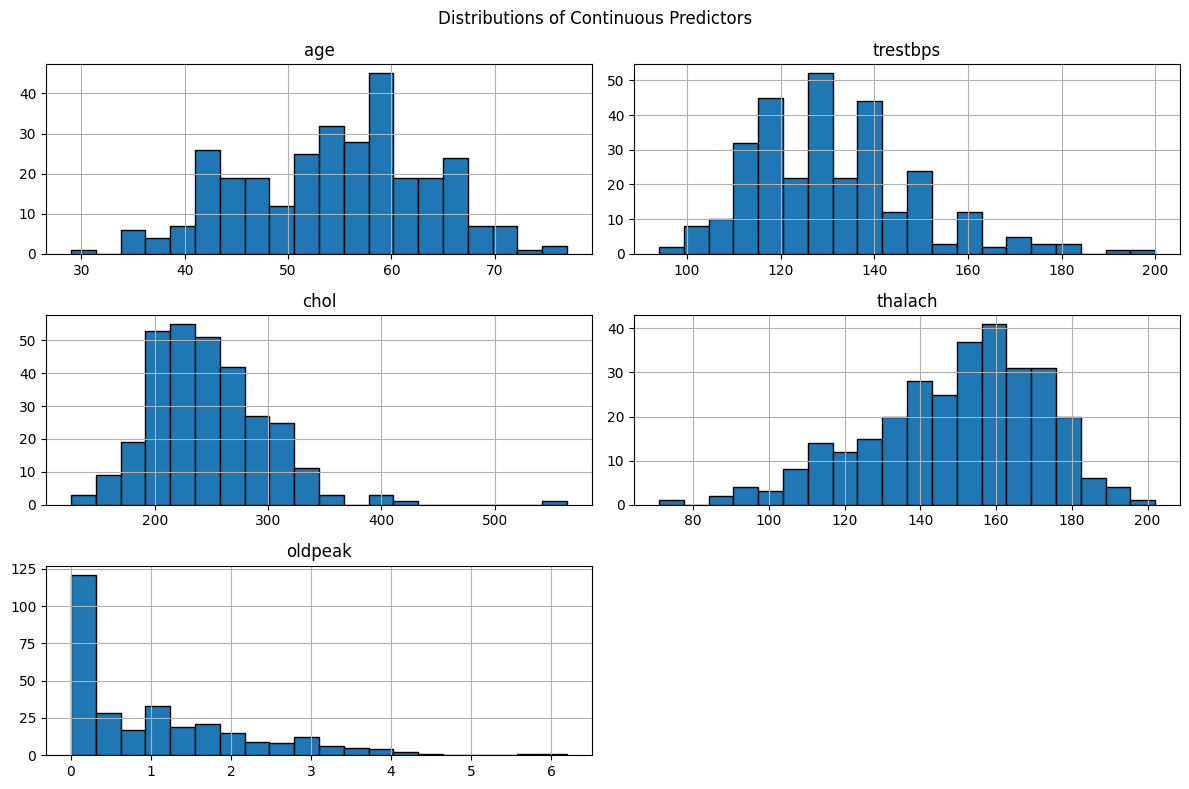

In [9]:
continuous_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

X[continuous_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distributions of Continuous Predictors")
plt.tight_layout()
plt.show()

I then examined the distribution of classes 0 and 1. The classes were fairly balanced, with 164 observations without heart disease and 139 with heart disease.

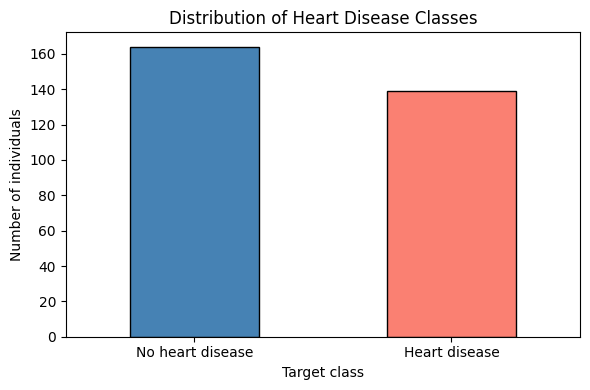

Class counts:
heart_disease
0    164
1    139
Name: count, dtype: int64


In [10]:
class_counts = y.value_counts().sort_index()

class_counts.plot(
    kind="bar",
    figsize=(6, 4),
    color=["steelblue", "salmon"],
    edgecolor="black"
)

plt.xticks(
    ticks=[0, 1],
    labels=["No heart disease", "Heart disease"],
    rotation=0
)
plt.xlabel("Target class")
plt.ylabel("Number of individuals")
plt.title("Distribution of Heart Disease Classes")
plt.tight_layout()
plt.show()

print("Class counts:")
print(class_counts)

# Train-Test Split

I split the dataset into 80% training data and 20% testing data. I used stratification to maintain similar class proportions in both sets and a fixed random state to make the split reproducible.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (242, 13)
X_test: (61, 13)
y_train: (242,)
y_test: (61,)


# Correlation Analysis

I then examined correlations between the predictors and the target using the training data. I displayed the results numerically and through a heatmap to help identify potentially useful predictors. I sorted out the correlations based on the highrst absolute value.

In [12]:
training_data = X_train.copy()
training_data["heart_disease"] = y_train

correlation_matrix = training_data.corr()

target_correlations = (
    correlation_matrix["heart_disease"]
    .drop("heart_disease")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

print("Correlations with heart disease:")
print(target_correlations.round(3))

Correlations with heart disease:
thal        0.550
ca          0.453
exang       0.420
thalach    -0.409
cp          0.401
oldpeak     0.392
slope       0.323
sex         0.308
age         0.210
restecg     0.160
trestbps    0.136
chol        0.077
fbs         0.046
Name: heart_disease, dtype: float64


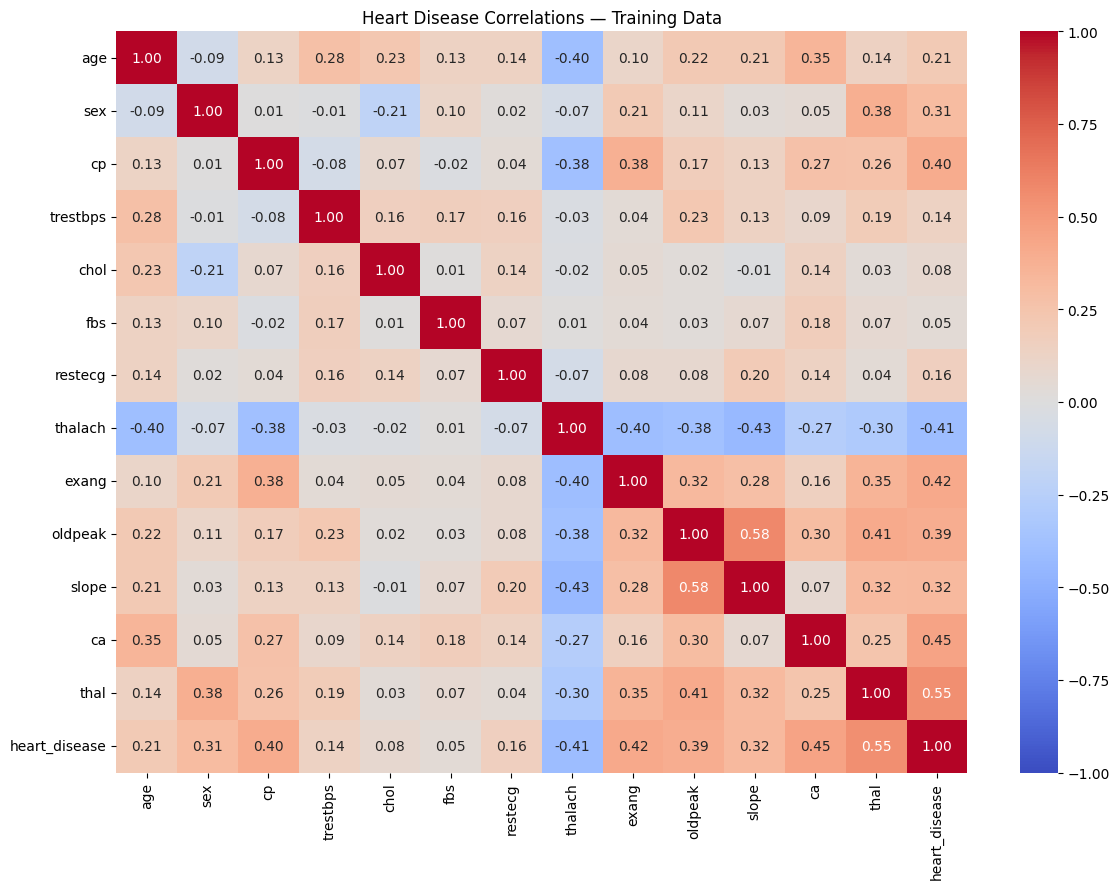

In [13]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Heart Disease Correlations — Training Data")
plt.tight_layout()
plt.show()

The selected features were thal, ca, exang, cp, oldpeak, slope, and thalach, based on their relatively strong correlations with the target. I then created training and testing subsets containing only these seven features.

In [14]:
selected_features = [
    "thal",
    "ca",
    "exang",
    "cp",
    "oldpeak",
    "slope",
    "thalach"
]

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print(X_train_selected.head())

print("\nSelected training shape:", X_train_selected.shape)
print("Selected testing shape:", X_test_selected.shape)

     thal   ca  exang  cp  oldpeak  slope  thalach
180   7.0  0.0      0   4      0.5      2      166
208   3.0  0.0      0   2      0.0      1      155
167   3.0  1.0      1   2      0.0      1      159
105   7.0  0.0      0   2      0.0      1      156
297   7.0  0.0      1   4      0.2      2      123

Selected training shape: (242, 7)
Selected testing shape: (61, 7)


#Preprocessing
I divided the selected predictors into numerical and categorical groups. I defined median imputation for missing numerical values and most-frequent imputation for missing categorical values. I also included standardization for numerical predictors and one-hot encoding for categorical predictors, combining these steps into a single preprocessor.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["ca", "oldpeak", "thalach"]
categorical_features = ["thal", "exang", "cp", "slope"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing defined.")

Preprocessing defined.


I separately demonstrated MinMax normalization on the selected numeric training predictors after median imputation, confirming that each feature ranged from 0 to 1.

In [16]:
from sklearn.preprocessing import MinMaxScaler

normalization_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("normalizer", MinMaxScaler())
])

X_train_normalized = normalization_pipeline.fit_transform(
    X_train_selected[numeric_features]
)

normalized_summary = pd.DataFrame({
    "Feature": numeric_features,
    "Minimum": X_train_normalized.min(axis=0),
    "Maximum": X_train_normalized.max(axis=0)
})

print(normalized_summary.round(3))

   Feature  Minimum  Maximum
0       ca      0.0      1.0
1  oldpeak      0.0      1.0
2  thalach      0.0      1.0


# Decision Tree
I started by training a baseline Decision Tree using the seven selected predictors and a fixed random state for reproducibility

In [17]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

decision_tree_pipeline.fit(X_train_selected, y_train)

print("Baseline Decision Tree trained successfully.")

Baseline Decision Tree trained successfully.


I performed five-fold stratified cross-validation to evaluate the baseline model using accuracy, precision, recall, F1 score, and ROC AUC.

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv = cross_validate(
    decision_tree_pipeline,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = baseline_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.765 ± 0.032
precision: 0.755 ± 0.033
recall: 0.721 ± 0.054
f1: 0.737 ± 0.042
roc_auc: 0.761 ± 0.034


I then used GridSearchCV to tune the Decision Tree’s hyperparameters, selecting the configuration with the highest mean cross-validation ROC AUC. The best configuration used entropy as the splitting criterion, a maximum depth of 3, a minimum of 1 sample per leaf, and a minimum of 2 samples to split a node, achieving a mean cross-validation ROC AUC of 0.864.

In [19]:
from sklearn.model_selection import GridSearchCV

tree_param_grid = {
    "model__max_depth": [2, 3, 4, 5, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__criterion": ["gini", "entropy"]
}

tree_grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=tree_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

tree_grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(tree_grid_search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(round(tree_grid_search.best_score_, 3))

Best parameters:
{'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}

Best cross-validation ROC AUC:
0.864


I displayed the top ten hyperparameter combinations ranked by mean validation ROC AUC, along with their training scores and variation across folds.

In [20]:
tree_results = pd.DataFrame(tree_grid_search.cv_results_)

tree_results_table = tree_results[[
    "param_model__criterion",
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__min_samples_split",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False)

print(tree_results_table.head(10).round(3))

   param_model__criterion param_model__max_depth  \
74                entropy                      3   
72                entropy                      3   
73                entropy                      3   
75                entropy                      3   
76                entropy                      3   
77                entropy                      3   
21                   gini                      3   
22                   gini                      3   
23                   gini                      3   
16                   gini                      3   

    param_model__min_samples_leaf  param_model__min_samples_split  \
74                              1                              10   
72                              1                               2   
73                              1                               5   
75                              3                               2   
76                              3                               5   
77           

I then plotted the tuned Decision Tree to visualize its feature splits and how they lead to predictions of heart disease or no heart disease.

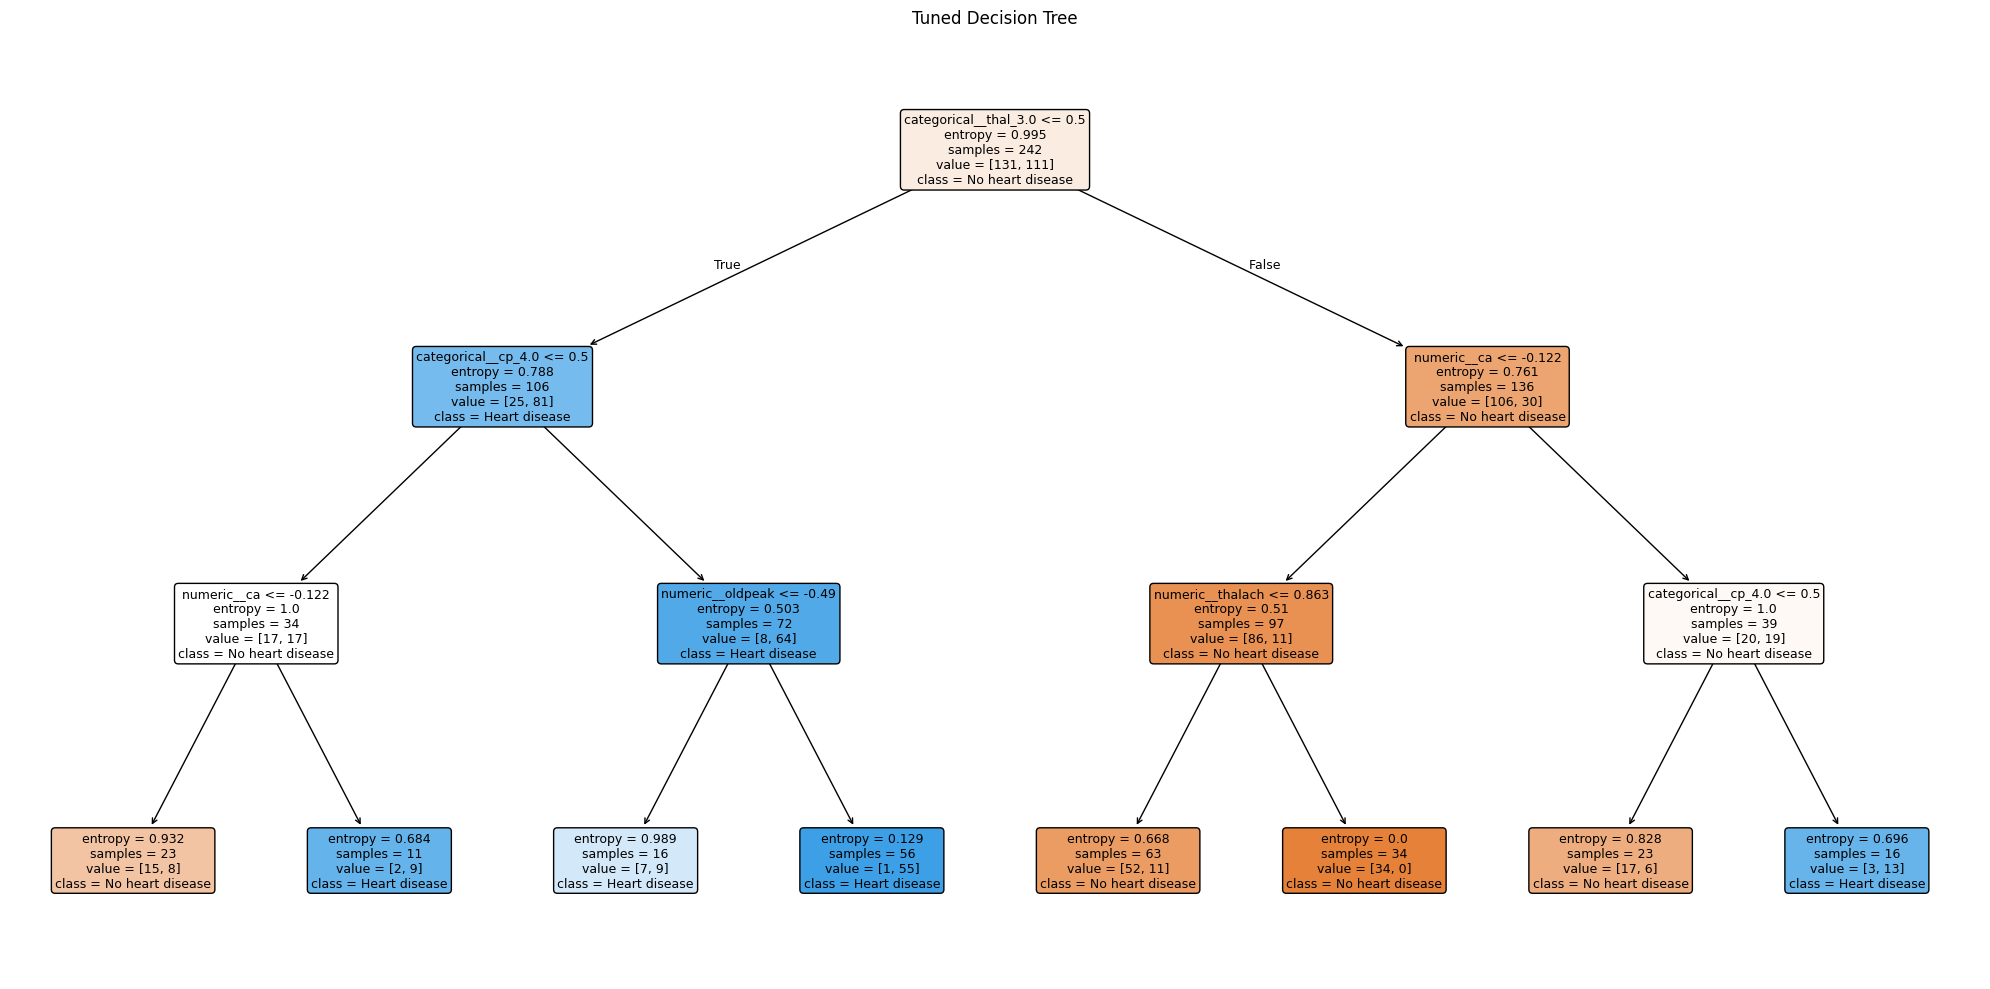

In [21]:
from sklearn.tree import plot_tree

best_tree = tree_grid_search.best_estimator_

feature_names = (
    best_tree.named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    best_tree.named_steps["model"],
    feature_names=feature_names,
    class_names=["No heart disease", "Heart disease"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Tuned Decision Tree")
plt.tight_layout()
plt.show()

# Random Forest Classifier
Next, I trained a baseline Random Forest classifier using the same preprocessing pipeline and seven selected predictors.

In [22]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ))
])

random_forest_pipeline.fit(X_train_selected, y_train)

print("Baseline Random Forest trained successfully.")

Baseline Random Forest trained successfully.


I performed five-fold stratified cross-validation to evaluate the baseline model using accuracy, precision, recall, F1 score, and ROC AUC.

In [23]:
forest_baseline_cv = cross_validate(
    random_forest_pipeline,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = forest_baseline_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.814 ± 0.022
precision: 0.812 ± 0.008
recall: 0.774 ± 0.078
f1: 0.790 ± 0.040
roc_auc: 0.879 ± 0.015


I then used GridSearchCV to tune the Random Forest’s hyperparameters, selecting the configuration with the highest mean cross-validation ROC AUC. The best configuration used 200 trees, no maximum depth limit, a minimum of 5 samples per leaf, and the square root of the number of features considered at each split, achieving a mean cross-validation ROC AUC of 0.897.

In [24]:
forest_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [1, 3, 5],
    "model__max_features": ["sqrt", 0.75]
}

forest_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=forest_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

forest_grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(forest_grid_search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(round(forest_grid_search.best_score_, 3))

Best parameters:
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 200}

Best cross-validation ROC AUC:
0.897


I displayed the top ten hyperparameter combinations ranked by mean validation ROC AUC, along with their training scores and variation across folds.

In [25]:
forest_results = pd.DataFrame(forest_grid_search.cv_results_)

forest_results_table = forest_results[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__max_features",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False)

print(forest_results_table.head(10).round(3))

best_forest = forest_grid_search.best_estimator_

    param_model__n_estimators param_model__max_depth  \
29                        200                   None   
17                        200                      5   
13                        200                      5   
1                         200                      3   
3                         200                      3   
5                         200                      3   
4                         100                      3   
14                        100                      5   
2                         100                      3   
12                        100                      5   

    param_model__min_samples_leaf param_model__max_features  mean_train_score  \
29                              5                      sqrt             0.941   
17                              5                      sqrt             0.938   
13                              1                      sqrt             0.973   
1                               1                      sqrt

I then plotted one tree from the tuned Random Forest to visualize its feature splits and how they contribute to predictions of heart disease or no heart disease, limiting the display to a depth of 3 for readability.

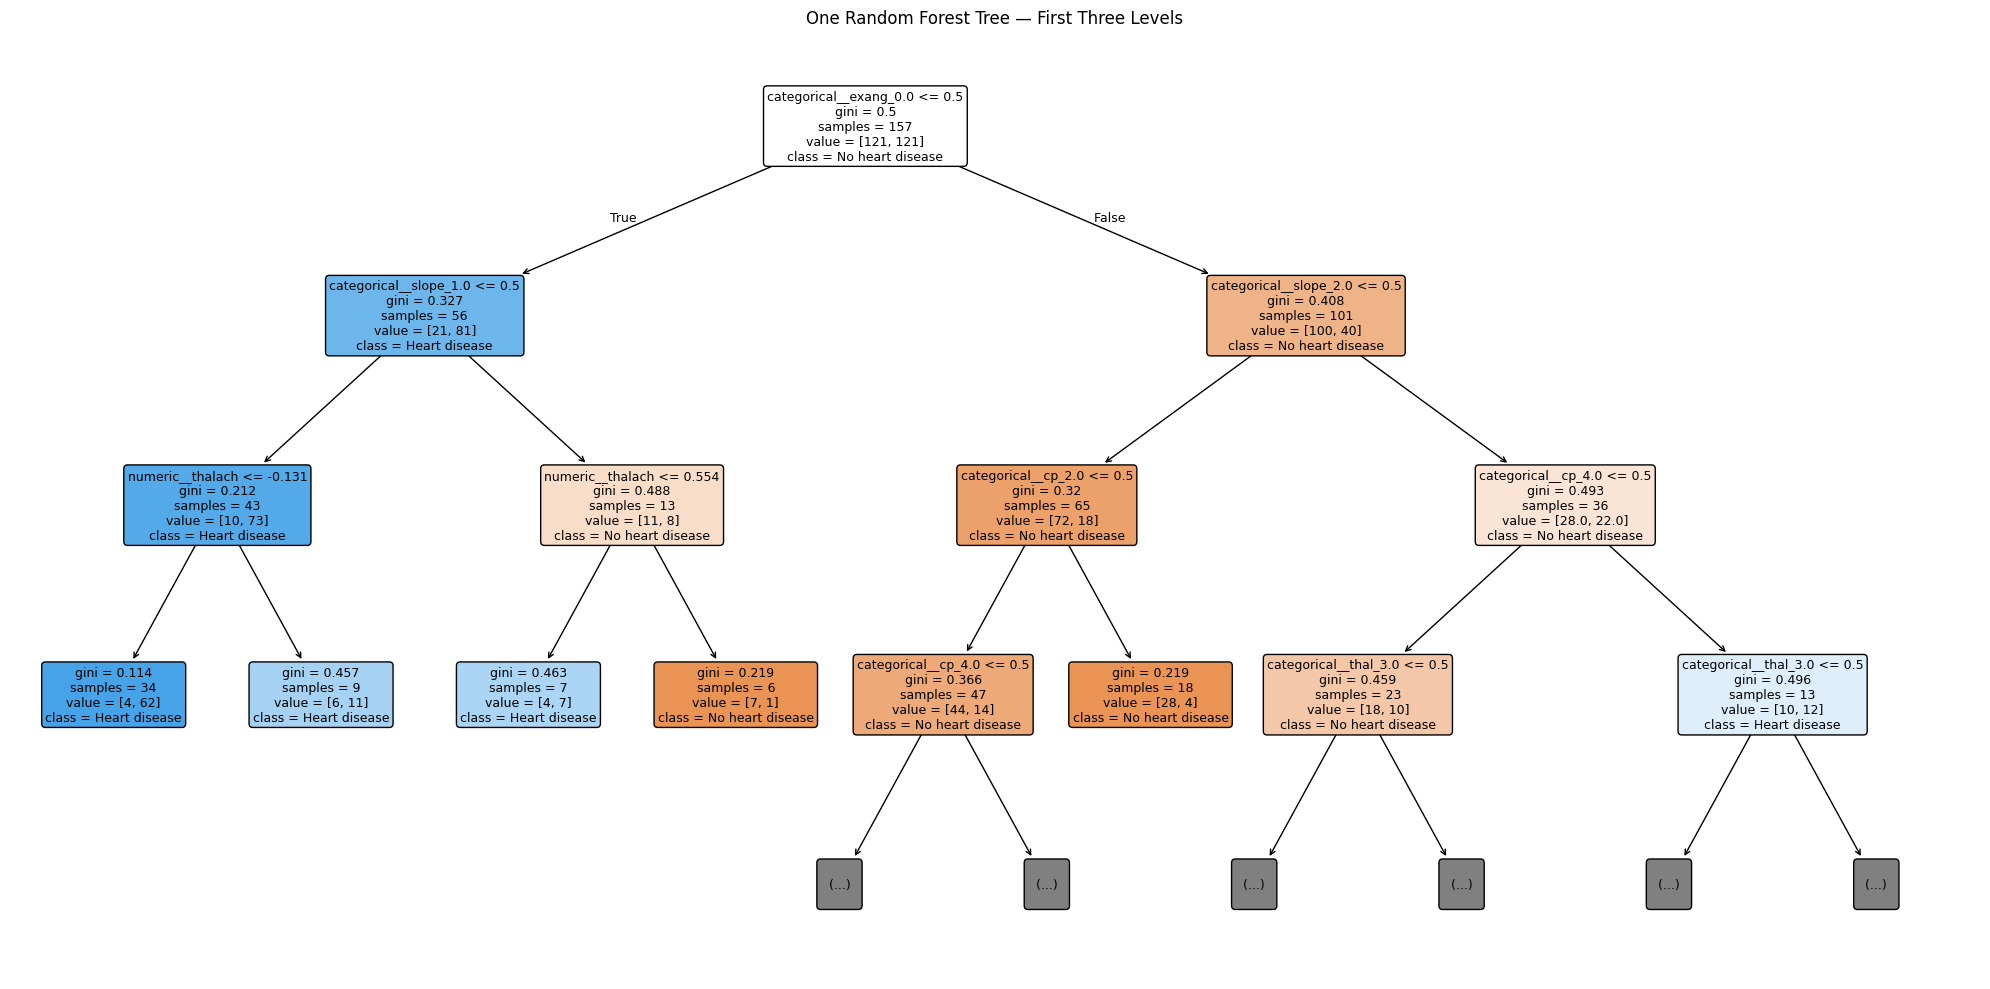

In [26]:
forest_feature_names = (
    best_forest.named_steps["preprocessor"]
    .get_feature_names_out()
)

forest_tree = best_forest.named_steps["model"].estimators_[0]

plt.figure(figsize=(20, 10))

plot_tree(
    forest_tree,
    feature_names=forest_feature_names,
    class_names=["No heart disease", "Heart disease"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One Random Forest Tree — First Three Levels")
plt.tight_layout()
plt.show()

#AdaBoost Classifier
Next, I trained a baseline AdaBoost classifier using the same preprocessing pipeline and seven selected predictors.

In [27]:
from sklearn.ensemble import AdaBoostClassifier

adaboost_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", AdaBoostClassifier(
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

adaboost_pipeline.fit(X_train_selected, y_train)

print("Baseline AdaBoost trained successfully.")

Baseline AdaBoost trained successfully.


I performed five-fold stratified cross-validation to evaluate the baseline model using accuracy, precision, recall, F1 score, and ROC AUC.

In [28]:
adaboost_baseline_cv = cross_validate(
    adaboost_pipeline,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = adaboost_baseline_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.835 ± 0.033
precision: 0.828 ± 0.033
recall: 0.809 ± 0.093
f1: 0.815 ± 0.045
roc_auc: 0.886 ± 0.029


I then used GridSearchCV to tune AdaBoost’s hyperparameters, selecting the configuration with the highest mean cross-validation ROC AUC. The best configuration used a learning rate of 0.01 and 200 estimators, achieving a mean cross-validation ROC AUC of 0.893.

In [29]:
adaboost_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.1, 0.5, 1.0]
}

adaboost_grid_search = GridSearchCV(
    estimator=adaboost_pipeline,
    param_grid=adaboost_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

adaboost_grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(adaboost_grid_search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(round(adaboost_grid_search.best_score_, 3))

best_adaboost = adaboost_grid_search.best_estimator_

Best parameters:
{'model__learning_rate': 0.01, 'model__n_estimators': 200}

Best cross-validation ROC AUC:
0.893


I displayed the top ten hyperparameter combinations ranked by mean validation ROC AUC, along with their training scores and variation across folds.

In [30]:
adaboost_results = pd.DataFrame(adaboost_grid_search.cv_results_)

adaboost_results_table = adaboost_results[[
    "param_model__n_estimators",
    "param_model__learning_rate",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False)

print(adaboost_results_table.head(10).round(3))

   param_model__n_estimators  param_model__learning_rate  mean_train_score  \
2                        200                        0.01             0.910   
3                         50                        0.10             0.916   
4                        100                        0.10             0.920   
5                        200                        0.10             0.922   
9                         50                        1.00             0.933   
6                         50                        0.50             0.922   
7                        100                        0.50             0.926   
8                        200                        0.50             0.932   
1                        100                        0.01             0.893   
0                         50                        0.01             0.880   

   mean_test_score  std_test_score  
2            0.893           0.023  
3            0.891           0.026  
4            0.888           0

I then plotted the first tree in the tuned AdaBoost classifier to visualize its feature split and how it contributes to predictions of heart disease or no heart disease.

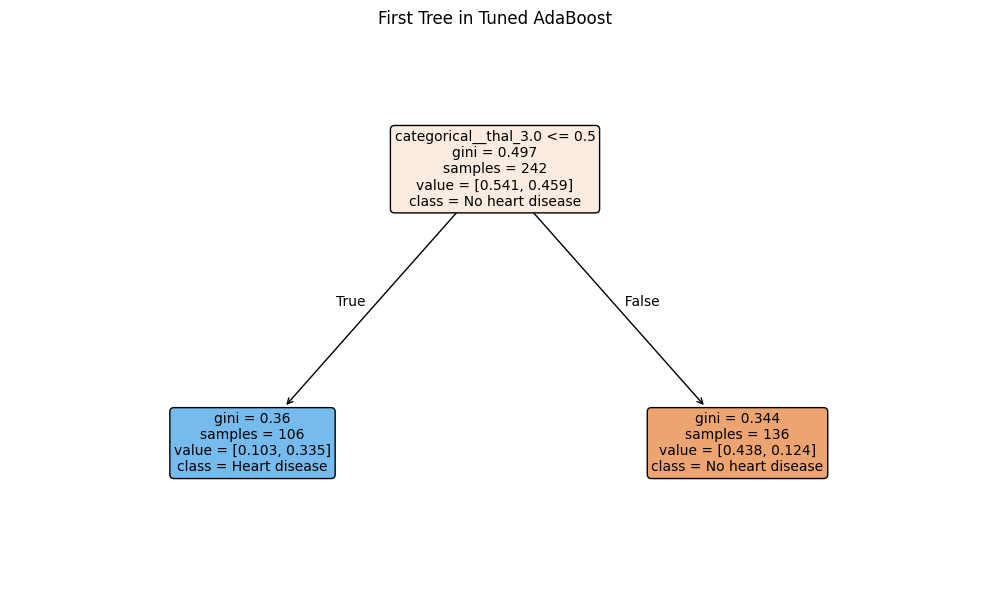

In [31]:
adaboost_feature_names = (
    best_adaboost.named_steps["preprocessor"]
    .get_feature_names_out()
)

adaboost_tree = best_adaboost.named_steps["model"].estimators_[0]

plt.figure(figsize=(10, 6))

plot_tree(
    adaboost_tree,
    feature_names=adaboost_feature_names,
    class_names=["No heart disease", "Heart disease"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("First Tree in Tuned AdaBoost")
plt.tight_layout()
plt.show()

#XGBoost Classifier
I trained a baseline XGBoost classifier using the same preprocessing pipeline and seven selected predictors.

In [32]:
!pip install xgboost

In [33]:
from xgboost import XGBClassifier

xgboost_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

xgboost_pipeline.fit(X_train_selected, y_train)

print("Baseline XGBoost trained successfully.")

Baseline XGBoost trained successfully.


I performed five-fold stratified cross-validation to evaluate the baseline model using accuracy, precision, recall, F1 score, and ROC AUC.

In [34]:
xgboost_baseline_cv = cross_validate(
    xgboost_pipeline,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = xgboost_baseline_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.773 ± 0.031
precision: 0.759 ± 0.064
recall: 0.757 ± 0.067
f1: 0.753 ± 0.028
roc_auc: 0.849 ± 0.027


I then used GridSearchCV to tune XGBoost’s hyperparameters, selecting the configuration with the highest mean cross-validation ROC AUC. The best configuration used a learning rate of 0.1, a maximum depth of 1, a minimum child weight of 5, and 100 estimators, achieving a mean cross-validation ROC AUC of 0.899.

In [35]:
xgboost_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [1, 2, 3],
    "model__learning_rate": [0.01, 0.1],
    "model__min_child_weight": [1, 5]
}

xgboost_grid_search = GridSearchCV(
    estimator=xgboost_pipeline,
    param_grid=xgboost_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

xgboost_grid_search.fit(X_train_selected, y_train)

print("Best parameters:")
print(xgboost_grid_search.best_params_)

print("\nBest cross-validation ROC AUC:")
print(round(xgboost_grid_search.best_score_, 3))

best_xgboost = xgboost_grid_search.best_estimator_

Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__min_child_weight': 5, 'model__n_estimators': 100}

Best cross-validation ROC AUC:
0.899


I displayed the top ten hyperparameter combinations ranked by mean validation ROC AUC, along with their training scores and variation across folds.

In [36]:
xgboost_results = pd.DataFrame(xgboost_grid_search.cv_results_)

xgboost_results_table = xgboost_results[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__learning_rate",
    "param_model__min_child_weight",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].sort_values("mean_test_score", ascending=False)

print(xgboost_results_table.head(10).round(3))

    param_model__n_estimators  param_model__max_depth  \
22                        100                       1   
23                        200                       1   
18                         50                       1   
21                         50                       1   
19                        100                       1   
27                         50                       2   
33                         50                       3   
2                         200                       1   
5                         200                       1   
20                        200                       1   

    param_model__learning_rate  param_model__min_child_weight  \
22                        0.10                              5   
23                        0.10                              5   
18                        0.10                              1   
21                        0.10                              5   
19                        0.10                 

I extracted the first tree from the tuned XGBoost model and displayed its split details and leaf contributions using readable feature names.

In [37]:
xgboost_feature_names = (
    best_xgboost.named_steps["preprocessor"]
    .get_feature_names_out()
)

first_tree = (
    best_xgboost.named_steps["model"]
    .get_booster()
    .trees_to_dataframe()
)

first_tree = first_tree[first_tree["Tree"] == 0].copy()

feature_mapping = {
    f"f{i}": name
    for i, name in enumerate(xgboost_feature_names)
}

first_tree["Feature"] = first_tree["Feature"].replace(feature_mapping)

print(first_tree[[
    "Node", "Feature", "Split", "Yes", "No", "Missing", "Gain", "Cover"
]])

   Node                Feature  Split   Yes    No Missing      Gain      Cover
0     0  categorical__thal_3.0    1.0   0-1   0-2     0-2  68.53549  60.086777
1     1                   Leaf   <NA>  <NA>  <NA>    <NA>  0.118526     26.319
2     2                   Leaf   <NA>  <NA>  <NA>    <NA> -0.093133  33.767776


I then plotted the first tree in the tuned XGBoost classifier to visualize its feature split and how its leaf contributions influence predictions of heart disease or no heart disease.

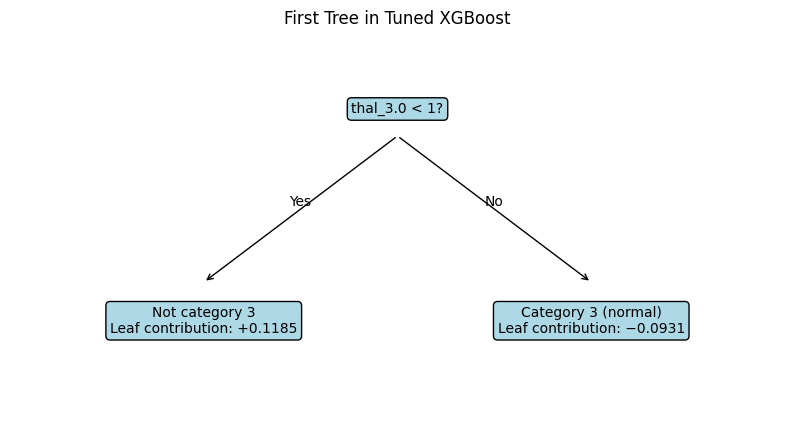

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")

nodes = [
    (0.5, 0.8, "thal_3.0 < 1?"),
    (0.25, 0.25, "Not category 3\nLeaf contribution: +0.1185"),
    (0.75, 0.25, "Category 3 (normal)\nLeaf contribution: −0.0931")
]

for x, y_pos, label in nodes:
    ax.text(
        x, y_pos, label,
        ha="center", va="center",
        transform=ax.transAxes,
        bbox=dict(boxstyle="round", facecolor="lightblue")
    )

for x, label in [(0.25, "Yes"), (0.75, "No")]:
    ax.annotate(
        "",
        xy=(x, 0.35),
        xytext=(0.5, 0.73),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="->")
    )
    ax.text(
        (0.5 + x) / 2, 0.55, label,
        ha="center",
        transform=ax.transAxes
    )

plt.title("First Tree in Tuned XGBoost")
plt.show()

I evaluated the four tuned models on the held-out test set using accuracy, precision, recall, F1 score, and ROC AUC, and displayed the results in a comparison table.

In [40]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

final_results = []
test_predictions = {}
test_probabilities = {}
tuned_models = {
    "Decision Tree": best_tree,
    "Random Forest": best_forest,
    "AdaBoost": best_adaboost,
    "XGBoost": best_xgboost
}

for model_name, model in tuned_models.items():
    predictions = model.predict(X_test_selected)
    probabilities = model.predict_proba(X_test_selected)[:, 1]

    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

final_comparison = pd.DataFrame(final_results)

print(final_comparison.round(3).to_string(index=False))

        Model  Accuracy  Precision  Recall    F1  ROC AUC
Decision Tree     0.869      0.857   0.857 0.857    0.862
Random Forest     0.869      0.833   0.893 0.862    0.952
     AdaBoost     0.869      0.857   0.857 0.857    0.927
      XGBoost     0.902      0.867   0.929 0.897    0.958


I plotted confusion matrices for all four models to compare correct predictions, false positives, and false negatives on the test set.

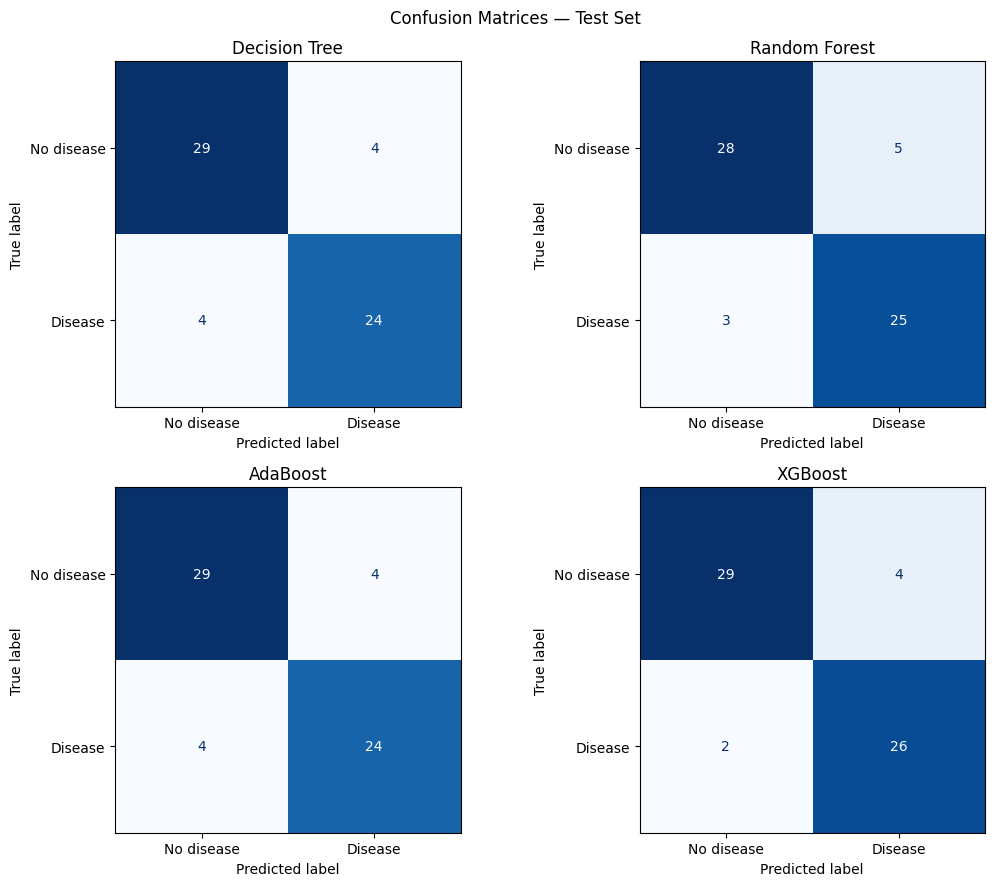

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for (model_name, predictions), ax in zip(
    test_predictions.items(), axes.ravel()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["No disease", "Disease"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(model_name)

plt.suptitle("Confusion Matrices — Test Set")
plt.tight_layout()
plt.show()

I plotted the test-set ROC curves to compare how well the four models distinguish between disease and no disease across different classification thresholds.

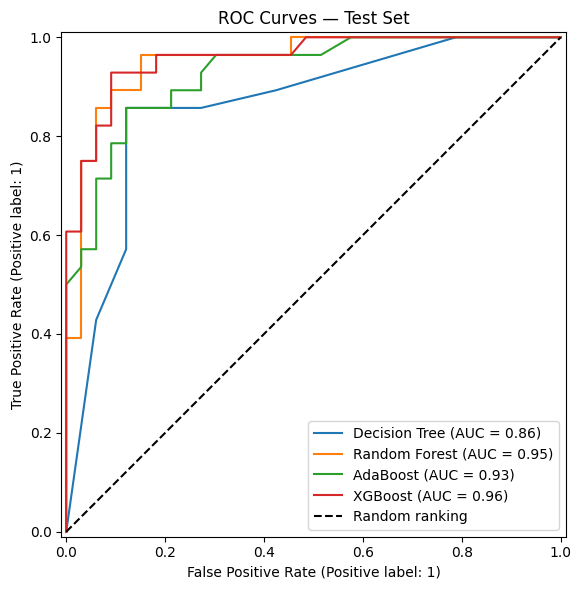

In [42]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Random ranking")
ax.set_title("ROC Curves — Test Set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

I plotted precision-recall curves to compare the models’ ability to detect heart disease while maintaining accurate positive predictions across different thresholds.

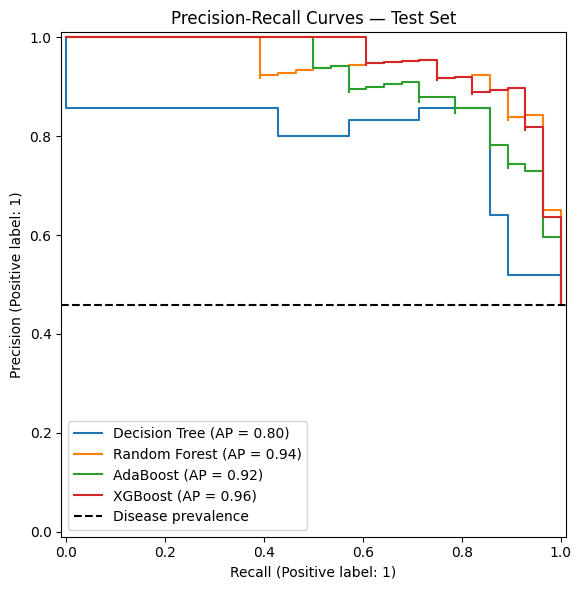

In [43]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probabilities in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=ax
    )

ax.axhline(
    y=y_test.mean(),
    color="black",
    linestyle="--",
    label="Disease prevalence"
)

ax.set_title("Precision-Recall Curves — Test Set")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()